# Conferência de documentos por vídeo · Vai de Primeira

**Nicho de interesse social:** quem vai a uma unidade de atendimento para tirar a Carteira de Identidade Nacional, renovar a CNH ou atualizar o Cadastro Único muitas vezes volta sem resolver porque a foto ou o papel do documento está ilegível. A Dona Francisca, 67 anos, perdeu uma viagem porque a certidão de casamento estava com reflexo.

**O que o sistema faz:** olha a foto ou o vídeo do documento e diz, antes de a pessoa sair de casa, se ele está bom, borrado, com reflexo ou cortado, com uma dica de como tirar de novo. **É triagem:** quem confere o documento é o atendente.

```
imagem ou quadro de vídeo
  → detector (YOLO11n): onde está o documento
  → recorte da caixa
  → qualidade (YOLO11n-cls): ok, borrado, reflexo ou cortado
  → tipo (OCR + palavras-chave): CNH, CIN, certidão, CPF ou comprovante
  → dica para o cidadão
```

Este notebook mostra os dados, a divisão sem vazamento, as métricas, a análise de erros, o processamento de vídeo, o desempenho, a escolha dos limiares e o teste com documentos brasileiros. O treino completo leva cerca de 45 minutos numa GPU; aqui usamos os pesos já treinados (`modelos/`) e os resultados gravados em `resultados/`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import cv2

RAIZ = Path.cwd()
if not (RAIZ / "src" / "conferencia.py").exists():
    RAIZ = RAIZ / "visao"
sys.path.insert(0, str(RAIZ / "src"))
ler = lambda nome: json.loads((RAIZ / "resultados" / nome).read_text(encoding="utf-8"))
import warnings
warnings.filterwarnings("ignore")


def mostrar(caminho, largura=10):
    plt.figure(figsize=(largura, largura * 0.6))
    plt.imshow(cv2.cvtColor(cv2.imread(str(caminho)), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

## 1. Dados e preparação
**MIDV-2020**, subconjunto `photo`: 1.000 fotos de celular de 1.000 documentos de identidade **fictícios** (10 tipos de documento, 8 condições de captura: pouca luz, reflexo, luz externa, distorção projetiva e fundos variados). Licença CC BY-SA 2.5; os rostos são gerados por IA, então não há dado pessoal real.

Preparação (`src/preparar_dados.py`):
- **Detector:** imagens redimensionadas para no máximo 1.024 px e uma caixa por documento, calculada a partir dos 4 cantos anotados.
- **Qualidade:** recorte da caixa com margem aleatória de 0 a 8% (o mesmo tipo de recorte que o detector entrega na prática), redimensionado para 448×288 px. As classes borrado, reflexo e cortado são geradas com intensidade aleatória; as fotos que já têm reflexo de luz real entram como reflexo e nunca como exemplo "ok". A normalização dos pixels é feita pelo próprio YOLO (0 a 1).

## 2. Divisão sem vazamento
A divisão é **por documento**, estratificada por tipo e condição: 640 treino, 180 validação, 180 teste. Todas as variações sintéticas de uma foto (borrada, com reflexo, cortada) ficam no mesmo conjunto da foto original. Se uma versão borrada de uma foto caísse no treino e a versão ok da mesma foto no teste, o modelo seria avaliado num documento que já viu. `src/verificar_divisao.py` confere isso automaticamente.

In [2]:
manifesto = pd.read_csv(RAIZ / "datasets" / "preparado" / "manifesto.csv") if (RAIZ / "datasets" / "preparado" / "manifesto.csv").exists() else None
if manifesto is not None:
    manifesto["documento"] = manifesto["tipo"] + "/" + manifesto["numero"].astype(str)  # um documento = tipo + número
    por_doc = manifesto.groupby("documento")["conjunto"].nunique()
    print(manifesto["conjunto"].value_counts().to_string())
    print(pd.crosstab(manifesto["condicao"], manifesto["conjunto"]))
    print("documentos que aparecem em mais de um conjunto:", int((por_doc > 1).sum()))
else:
    print("dataset não baixado nesta máquina; ver resultados gravados abaixo")

conjunto
treino       640
teste        180
validacao    180
conjunto             teste  treino  validacao
condicao                                     
distorcao_projetiva     30     140         30
documentos_no_fundo     20      60         20
luz_natural_externa     20      60         20
mesa_no_fundo           20      60         20
pouca_luz               30     140         30
reflexo_de_luz          20      60         20
tecido_no_fundo         20      60         20
teclado_no_fundo        20      60         20
documentos que aparecem em mais de um conjunto: 0


## 3. Etapa 1: detector (YOLO11n)
Transfer learning a partir do `yolo11n.pt` pré-treinado no COCO, ajustado para uma classe (`documento`), 640 px, até 50 épocas com parada antecipada.

In [3]:
det = ler("detector_metricas.json")
pd.DataFrame([det["teste"]]).rename(columns={"precisao": "precisão", "mAP50": "mAP@0,5", "mAP50_95": "mAP@0,5:0,95"})

,precisão,recall,"mAP@0,5","mAP@0,5:0,95"
0,0.9997,1.0,0.995,0.9937


## 4. Etapa 2: qualidade (YOLO11n-cls)
Classificação em 4 classes. Métricas no conjunto de teste: precisão, recall e F1 por classe e matriz de confusão.

In [4]:
q = ler("qualidade_metricas.json")["teste"]
print("acurácia", q["acuracia"], "· F1 macro", q["f1_macro"])
pd.DataFrame(q["por_classe"]).T.round(4)

acurácia 0.9971 · F1 macro 0.9971


,precision,recall,f1-score,support
ok,0.9877,1.0000,0.9938,160.0
borrado,1.0000,1.0000,1.0000,180.0
reflexo,1.0000,1.0000,1.0000,180.0
cortado,1.0000,0.9889,0.9944,180.0


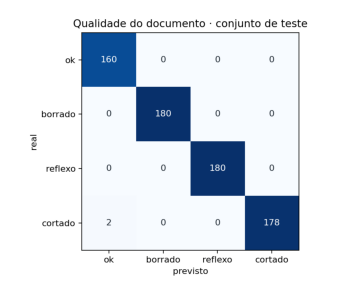

In [5]:
mostrar(RAIZ / "resultados" / "qualidade_matriz_confusao.png", 6)

## 5. Ponta a ponta e análise de erros
Avaliação do caminho completo (detector → recorte → qualidade) em fotos reais do teste, sem degradação sintética.

**Uma correção que essa avaliação revelou:** na primeira versão, o classificador foi treinado com o documento retificado pelos 4 cantos. Sozinho, acertava 99,6%; de ponta a ponta, caía para 85,6%, porque o detector entrega uma caixa retangular com um pouco de fundo, e nas fotos com documento inclinado os triângulos de fundo eram confundidos com "cortado" ou "reflexo". Treinar com o mesmo tipo de recorte usado na inferência levou o ponta a ponta para 100%.

In [6]:
p = ler("ponta_a_ponta.json")
print(f"acerto de ponta a ponta: {p['acerto_geral']:.0%} em {p['fotos_teste']} fotos")
pd.DataFrame(p["por_condicao"]).T

acerto de ponta a ponta: 100% em 180 fotos


,acerto,fotos
distorcao_projetiva,1.0,30.0
documentos_no_fundo,1.0,20.0
luz_natural_externa,1.0,20.0
mesa_no_fundo,1.0,20.0
pouca_luz,1.0,30.0
reflexo_de_luz,1.0,20.0
tecido_no_fundo,1.0,20.0
teclado_no_fundo,1.0,20.0


**Erros que sobraram no classificador (2 de 700):** dois documentos "cortados" classificados como "ok", ambos sobre fundo de tecido escuro. A faixa escura que simula a parte fora da foto se confunde com o fundo, e o modelo não percebe onde o documento termina.

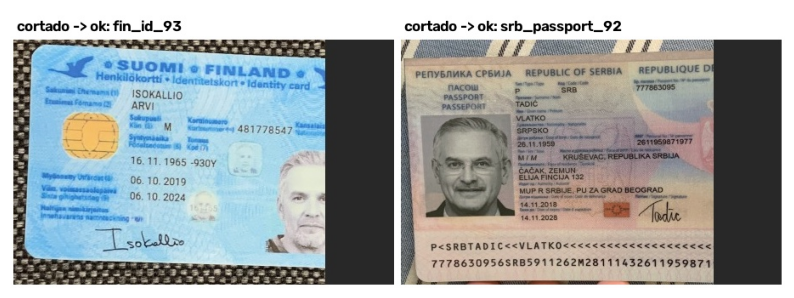

In [7]:
mostrar(RAIZ / "resultados" / "qualidade_erros.jpg", 10)

## 6. Processamento de vídeo
`src/processar_video.py` processa um vídeo quadro a quadro, desenha a caixa com a classe e a confiança e grava `resultados/sequencia_anotada.mp4` (360 quadros, média de 49 FPS). O OCR do tipo roda só a cada N quadros, porque é a etapa mais lenta.

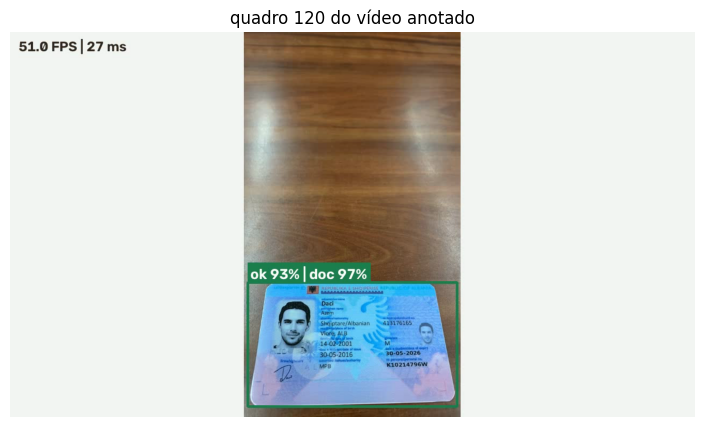

In [8]:
video = cv2.VideoCapture(str(RAIZ / "resultados" / "sequencia_anotada.mp4"))
video.set(cv2.CAP_PROP_POS_FRAMES, 120)
ok, quadro = video.read()
if ok:
    plt.figure(figsize=(9, 5)); plt.imshow(cv2.cvtColor(quadro, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("quadro 120 do vídeo anotado"); plt.show()

## 7. Latência e FPS

In [9]:
d = ler("desempenho.json")
print(d["hardware"], "·", d["dispositivo_inferencia"], "·", d["resolucao_entrada_px"])
pd.DataFrame({k: v for k, v in d.items() if isinstance(v, dict)}).T

Apple M4, 16 GB RAM, Darwin 25.6.0 · mps · 576x1024 (redimensionada para 640 px no detector e 224 px na qualidade)


,media_ms,mediana_ms,p95_ms,fps
detector,14.3,15.3,20.3,NaN
qualidade,6.4,6.1,7.2,NaN
modo_video_detector_mais_qualidade,20.7,21.5,27.6,48.3
ocr_tipo_documento_cpu,428.3,399.2,684.7,NaN


## 8. Limiares
| Limiar | Valor | Por quê |
|---|---|---|
| Confiança do detector | 0,50 | Na validação do MIDV-2020, o menor documento verdadeiro teve 0,938 e nenhuma caixa falsa passou de 0,25 |
| Confiança da qualidade | 0,60 | Abaixo disso o sistema não afirma o defeito: pede outra foto com boa luz. Só 1 de 700 ficou abaixo na validação |

O teste de campo abaixo mostrou que o limiar do detector, folgado no MIDV-2020, não é o problema com documentos brasileiros: as confianças ficaram muito abaixo de 0,50, e baixar o limiar aceitaria caixas erradas.

## 9. Teste de campo com documentos brasileiros fictícios
20 imagens de CIN, CNH e certidão fictícias, com marca de espécime, em 4 condições (`teste_campo/rotulos.csv`). É o primeiro contato do modelo com o layout brasileiro.

In [10]:
campo = ler("teste_campo.json")
print(json.dumps(campo["resumo"], indent=2, ensure_ascii=False))
pd.DataFrame(campo["imagens"])[["arquivo", "condicao_real", "conf_detector_max", "detectado", "qualidade_no_melhor_recorte", "tipo_previsto"]]

{
  "imagens": 20,
  "limiar_detector": 0.5,
  "detectados_no_limiar": 1,
  "conf_detector_mediana": 0.011,
  "qualidade_certa_entre_detectados": 1,
  "qualidade_certa_no_melhor_recorte": 9,
  "tipo_certo_entre_detectados": 1,
  "qualidade_prevista_no_melhor_recorte": {
    "null": 9,
    "ok": 6,
    "borrado": 2,
    "reflexo": 3
  }
}


,arquivo,condicao_real,conf_detector_max,detectado,qualidade_no_melhor_recorte,tipo_previsto
0,certidao_borrado_1.jpg,borrado,0.000,False,NaN,NaN
1,certidao_borrado_2.jpg,borrado,0.000,False,NaN,NaN
2,certidao_cortado_1.jpg,cortado,0.011,False,ok,NaN
3,certidao_ok_1.jpg,ok,0.000,False,NaN,NaN
4,certidao_reflexo_1.jpg,reflexo,0.000,False,NaN,NaN
5,certidao_reflexo_2.jpg,reflexo,0.000,False,NaN,NaN
6,cin_borrado_1.jpg,borrado,0.011,False,borrado,NaN
7,cin_borrado_2.jpg,borrado,0.000,False,NaN,NaN
8,cin_cortado_1.jpg,cortado,0.000,False,NaN,NaN
9,cin_cortado_2.jpg,cortado,0.000,False,NaN,NaN


**Resultado:** o detector treinado só com documentos estrangeiros achou o documento em 1 das 20 imagens. As confianças também caem quando a imagem é grande: reduzir para 512 px de largura subiu para 7 de 20. A causa principal é a mudança de domínio (layout, cores e proporções diferentes do MIDV-2020).

**O que fizemos:** `src/gerar_documentos_br.py` gera 750 fotos sintéticas de documentos brasileiros fictícios (CIN, CNH, CPF, certidão e conta de energia, com marca de espécime) sobre fundos procedurais, com perspectiva, rotação, reflexo, desfoque e compressão. Os fundos são diferentes do fundo das imagens do teste de campo, para que o teste continue medindo generalização. O detector foi ajustado com o MIDV-2020 + essas imagens e avaliado de novo nas mesmas 20 imagens.

In [11]:
ajuste = RAIZ / "resultados" / "teste_campo_ajustado.json"
if ajuste.exists():
    a = json.loads(ajuste.read_text(encoding="utf-8"))
    print(json.dumps(a["resumo"], indent=2, ensure_ascii=False))
    display(pd.DataFrame(a["imagens"])[["arquivo", "condicao_real", "conf_detector_max", "detectado", "qualidade_prevista", "tipo_previsto"]])

{
  "imagens": 20,
  "limiar_detector": 0.5,
  "detectados_no_limiar": 19,
  "conf_detector_mediana": 0.963,
  "qualidade_certa_entre_detectados": 13,
  "qualidade_certa_no_melhor_recorte": 13,
  "tipo_certo_entre_detectados": 12,
  "qualidade_prevista_no_melhor_recorte": {
    "borrado": 4,
    "null": 1,
    "ok": 10,
    "cortado": 1,
    "reflexo": 4
  }
}


,arquivo,condicao_real,conf_detector_max,detectado,qualidade_prevista,tipo_previsto
0,certidao_borrado_1.jpg,borrado,0.939,True,borrado,desconhecido
1,certidao_borrado_2.jpg,borrado,0.000,False,NaN,NaN
2,certidao_cortado_1.jpg,cortado,0.955,True,ok,certidao
3,certidao_ok_1.jpg,ok,0.961,True,ok,certidao
4,certidao_reflexo_1.jpg,reflexo,0.955,True,cortado,desconhecido
5,certidao_reflexo_2.jpg,reflexo,0.963,True,reflexo,certidao
6,cin_borrado_1.jpg,borrado,0.967,True,borrado,desconhecido
7,cin_borrado_2.jpg,borrado,0.949,True,borrado,desconhecido
8,cin_cortado_1.jpg,cortado,0.964,True,ok,desconhecido
9,cin_cortado_2.jpg,cortado,0.967,True,ok,cin


{'documentos': [{'tipo': 'cin', 'confianca': 0.971, 'qualidade': 'reflexo', 'confianca_qualidade': 1.0, 'dica': 'Tem reflexo no papel. Incline um pouco ou fuja da luz direta.', 'caixa': [202, 257, 1350, 994]}], 'latencia_ms': 3188}


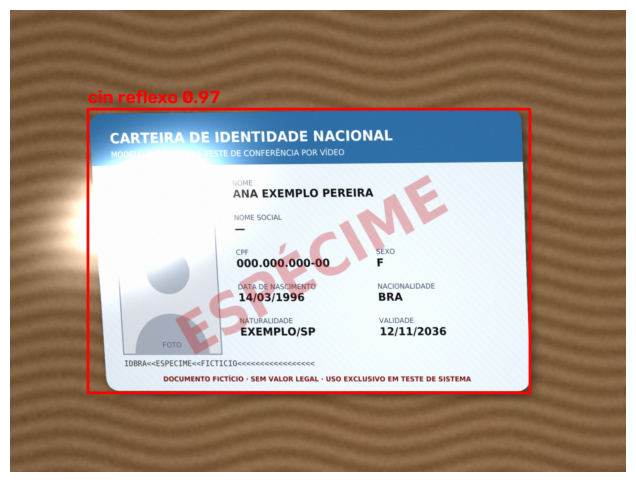

In [12]:
from conferencia import Conferencia
conf = Conferencia()
imagem = cv2.imread(str(RAIZ / "teste_campo" / "fotos" / "cin_reflexo_1.jpg"))
r = conf.analisar(imagem)
for d in r["documentos"]:
    x0, y0, x1, y1 = d["caixa"]
    cv2.rectangle(imagem, (x0, y0), (x1, y1), (0, 0, 255), 6)
    cv2.putText(imagem, f"{d['tipo']} {d['qualidade']} {d['confianca']:.2f}", (x0, max(40, y0 - 15)), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 255), 4)
print(r)
plt.figure(figsize=(9, 6)); plt.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

## 10. Limites e responsabilidade
- **Triagem, não decisão:** o sistema só sugere tirar outra foto. Quem aceita ou recusa o documento é o atendente.
- **Documentos sintéticos:** tanto o ajuste quanto o teste de campo usam documentos brasileiros gerados por computador. Falta testar com fotos de celular de documentos espécime impressos.
- **Borrado e cortado** foram avaliados com degradações sintéticas; só ok e reflexo têm rótulo real no MIDV-2020.
- **OCR do tipo** depende da legibilidade do texto; quando falha, o app pergunta à pessoa qual documento ela fotografou.
- **Privacidade:** a API não guarda as fotos. Em produção, o processamento poderia rodar no próprio celular (os modelos têm 5 MB e 3 MB).